# 📊 BÀI TẬP PHÂN TÍCH DỮ LIỆU KHÁCH HÀNG (CUSTOMER DATA ANALYSIS)
**Học phần:** Phân tích kinh doanh  
**Tập dữ liệu:** `customer.csv` 
**Học viên:** Đỗ Văn Đạt
**Lớp:** K28.PTKDA   

---
### 🎯 Mục tiêu bài tập:
1. Đánh giá cấu trúc dữ liệu, kiểu biến và số lượng quan sát.
2. Thống kê mô tả toàn diện cho biến định tính và định lượng.
3. Phân tích chi tiết độ tuổi (`Customer_Age`), phân bố địa lý (`state_cd`), phân nhóm tuổi.
4. Mã hóa biến (Binary & Dummy Encoding) và tính ma trận tương quan.
5. Trực quan hóa dữ liệu trực quan bằng biểu đồ Histogram, KDE, Heatmap và Boxplot.


## 📦 0. Cài đặt tự động các thư viện cần thiết
> Chạy ô code bên dưới để cài đặt `seaborn`, `matplotlib`, `pandas`, `scipy` vào đúng môi trường Python của Notebook.

In [2]:
# Tự động cài đặt thư viện vào Kernel hiện tại/go
%pip install -q seaborn matplotlib pandas scipy


You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


## 🛠️ 1. Khởi tạo môi trường & Đọc dữ liệu

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

# Cấu hình hiển thị
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Đọc file dữ liệu (tự động phát hiện đường dẫn)
data_path = 'customer.csv' if os.path.exists('customer.csv') else 'BA/code gửi/customer.csv'
df = pd.read_csv(data_path)

print(f"✅ Đã tải dữ liệu thành công! Kích thước: {df.shape[0]:,} dòng, {df.shape[1]} cột.")
df.head()

✅ Đã tải dữ liệu thành công! Kích thước: 10,108 dòng, 16 cột.


,Client_Num,Customer_Age,Gender,Dependent_Count,Education_Level,Marital_Status,state_cd,Zipcode,Car_Owner,House_Owner,Personal_loan,contact,Customer_Job,Income,Cust_Satisfaction_Score,Total_Trans_Ct
0,708082083,24,F,1,Uneducated,Single,FL,91750,no,yes,no,unknown,Businessman,202326,3,42
1,708083283,62,F,0,Unknown,Married,NJ,91750,no,no,no,cellular,Selfemployeed,5225,2,33
2,708084558,32,F,1,Unknown,Married,NJ,91750,yes,no,no,unknown,Selfemployeed,14235,2,20
3,708085458,38,M,2,Uneducated,Single,NY,91750,no,no,no,cellular,Blue-collar,45683,1,20
4,708086958,48,M,4,Graduate,Single,TX,91750,yes,yes,no,cellular,Businessman,59279,1,28


---
## 📌 CÂU 1: Số lượng quan sát, số lượng biến và kiểu dữ liệu từng biến
> **Yêu cầu:** Bộ dữ liệu có bao nhiêu quan sát và bao nhiêu biến? Kiểu dữ liệu của từng biến là gì?


In [4]:
# 1. Kích thước bộ dữ liệu
num_rows, num_cols = df.shape
print(f"• Số lượng quan sát (dòng): {num_rows:,}")
print(f"• Số lượng biến (cột): {num_cols}")

# 2. Bảng phân loại kiểu dữ liệu từng biến
var_summary = pd.DataFrame({
    'Tên biến': df.columns,
    'Kiểu dữ liệu (Dtype)': df.dtypes.values,
    'Số lượng Non-Null': df.notnull().sum().values,
    'Số giá trị Unique': df.nunique().values,
    'Phân loại Thống kê': [
        'Định lượng rời rạc (ID)',
        'Định lượng (Tỷ lệ)',
        'Định tính danh nghĩa (Nominal)',
        'Định lượng rời rạc',
        'Định tính thứ bậc (Ordinal)',
        'Định tính danh nghĩa (Nominal)',
        'Định tính danh nghĩa (Nominal)',
        'Định tính danh nghĩa (Mã vùng)',
        'Định tính nhị phân (Binary)',
        'Định tính nhị phân (Binary)',
        'Định tính nhị phân (Binary)',
        'Định tính danh nghĩa (Nominal)',
        'Định tính danh nghĩa (Nominal)',
        'Định lượng liên tục (Tỷ lệ)',
        'Định tính thứ bậc / Điểm số',
        'Định lượng rời rạc'
    ]
})
var_summary

• Số lượng quan sát (dòng): 10,108
• Số lượng biến (cột): 16


,Tên biến,Kiểu dữ liệu (Dtype),Số lượng Non-Null,Số giá trị Unique,Phân loại Thống kê
0,Client_Num,int64,10108,10108,Định lượng rời rạc (ID)
1,Customer_Age,int64,10108,50,Định lượng (Tỷ lệ)
2,Gender,object,10108,2,Định tính danh nghĩa (Nominal)
3,Dependent_Count,int64,10108,6,Định lượng rời rạc
4,Education_Level,object,10108,6,Định tính thứ bậc (Ordinal)
5,Marital_Status,object,10108,3,Định tính danh nghĩa (Nominal)
6,state_cd,object,10108,28,Định tính danh nghĩa (Nominal)
7,Zipcode,int64,10108,41,Định tính danh nghĩa (Mã vùng)
8,Car_Owner,object,10108,2,Định tính nhị phân (Binary)
9,House_Owner,object,10108,2,Định tính nhị phân (Binary)


---
## 📌 CÂU 2: Lập bảng tổng quan mô tả toàn bộ dữ liệu
> **Yêu cầu:** Lập bảng tổng quan mô tả toàn bộ dữ liệu (cả biến định lượng và định tính)


In [8]:
# A. Thống kê mô tả biến định lượng
quant_desc = df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
quant_desc.columns = ['Số lượng', 'Trung bình', 'Độ lệch chuẩn', 'Min', 'Q1 (25%)', 'Trung vị (50%)', 'Q3 (75%)', 'Max']
print('=== BẢNG THỐNG KÊ BIẾN ĐỊNH LƯỢNG ===')
display(quant_desc)

# B. Thống kê mô tả biến định tính
qual_desc = df.describe(include=['object']).T[['count', 'unique', 'top', 'freq']]
qual_desc.columns = ['Số lượng', 'Số nhóm riêng biệt', 'Giá trị phổ biến nhất', 'Tần số cao nhất']
qual_desc['Tỷ trọng nhóm phổ biến (%)'] = (qual_desc['Tần số cao nhất'] / len(df)) * 100
print('\n=== BẢNG THỐNG KÊ BIẾN ĐỊNH TÍNH ===')
display(qual_desc)


=== BẢNG THỐNG KÊ BIẾN ĐỊNH LƯỢNG ===


,Số lượng,Trung bình,Độ lệch chuẩn,Min,Q1 (25%),Trung vị (50%),Q3 (75%),Max
Client_Num,10108.0000,739010423.5768,36736228.8592,708082083.0000,713026683.0000,717903745.5000,772798945.5000,827890758.0000
Customer_Age,10108.0000,46.2744,8.0879,21.0000,41.0000,46.0000,52.0000,73.0000
Dependent_Count,10108.0000,2.3454,1.2995,0.0000,1.0000,2.0000,3.0000,5.0000
Zipcode,10108.0000,91663.0718,1693.0939,53010.0000,91750.0000,91750.0000,91750.0000,99504.0000
Income,10108.0000,56976.1020,46183.7182,1250.0000,22635.7500,44768.5000,76392.7500,239791.0000
Cust_Satisfaction_Score,10108.0000,3.1893,1.2631,1.0000,2.0000,3.0000,4.0000,5.0000
Total_Trans_Ct,10108.0000,64.8115,23.4460,10.0000,45.0000,67.0000,81.0000,139.0000



=== BẢNG THỐNG KÊ BIẾN ĐỊNH TÍNH ===


,Số lượng,Số nhóm riêng biệt,Giá trị phổ biến nhất,Tần số cao nhất,Tỷ trọng nhóm phổ biến (%)
Gender,10108,2,F,5880,58.1717
Education_Level,10108,6,Graduate,4134,40.8983
Marital_Status,10108,3,Married,5128,50.7321
state_cd,10108,28,CA,2468,24.4163
Car_Owner,10108,2,no,6044,59.7942
House_Owner,10108,2,no,5390,53.3241
Personal_loan,10108,2,no,8822,87.2774
contact,10108,3,cellular,7457,73.7732
Customer_Job,10108,6,Selfemployeed,2575,25.4749


---
## 📌 CÂU 3: Thống kê mô tả đầy đủ cho biến `Customer_Age`
> **Yêu cầu:** Tính đầy đủ các thống kê mô tả cho biến Age: trung bình, trung vị, mốt, phương sai, độ lệch chuẩn, các tứ phân vị, IQR, hệ số biến thiên.


In [18]:
age = df['Customer_Age']

mean_age = age.mean()
median_age = age.median()
mode_age = age.mode()[0]
var_age = age.var()
std_age = age.std()
q1 = age.quantile(0.25)
q2 = age.quantile(0.50)
q3 = age.quantile(0.75)
iqr = q3 - q1
cv = (std_age / mean_age) * 100

age_stats_df = pd.DataFrame({
    'Chỉ tiêu thống kê': [
        '1. Trung bình (Mean)', 
        '2. Trung vị (Median)', 
        '3. Mốt (Mode)', 
        '4. Phương sai (Sample Variance)', 
        '5. Độ lệch chuẩn (Sample Std Dev)', 
        '6. Tứ phân vị thứ nhất (Q1 - 25%)', 
        '7. Tứ phân vị thứ hai (Q2 - 50%)', 
        '8. Tứ phân vị thứ ba (Q3 - 75%)', 
        '9. Khoảng tứ phân vị (IQR / TQR)', 
        '10. Hệ số biến thiên (CV %)'
    ],
    'Công thức tính': [
        'sum(x) / n',
        'Giá trị nằm chính giữa tập dữ liệu sắp thứ tự',
        'Giá trị có tần số xuất hiện cao nhất',
        's² = sum(x - mean)² / (n - 1)',
        's = sqrt(s²)',
        '25th Percentile',
        '50th Percentile',
        '75th Percentile',
        'Q3 - Q1',
        '(s / mean) * 100'
    ],
    'Giá trị': [
        mean_age, median_age, mode_age, var_age, std_age,
        q1, q2, q3, iqr, cv
    ]
})
age_stats_df

,Chỉ tiêu thống kê,Công thức tính,Giá trị
0,1. Trung bình (Mean),sum(x) / n,46.2744
1,2. Trung vị (Median),Giá trị nằm chính giữa tập dữ liệu sắp thứ tự,46.0000
2,3. Mốt (Mode),Giá trị có tần số xuất hiện cao nhất,44.0000
3,4. Phương sai (Sample Variance),s² = sum(x - mean)² / (n - 1),65.4137
4,5. Độ lệch chuẩn (Sample Std Dev),s = sqrt(s²),8.0879
5,6. Tứ phân vị thứ nhất (Q1 - 25%),25th Percentile,41.0000
6,7. Tứ phân vị thứ hai (Q2 - 50%),50th Percentile,46.0000
7,8. Tứ phân vị thứ ba (Q3 - 75%),75th Percentile,52.0000
8,9. Khoảng tứ phân vị (IQR / TQR),Q3 - Q1,11.0000
9,10. Hệ số biến thiên (CV %),(s / mean) * 100,17.4781


---
## 📌 CÂU 4: Phân bố khách hàng theo Thành phố/Bang (`state_cd`)
> **Yêu cầu:** Khách hàng phân bố theo thành phố ra sao? Thành phố nào đông nhất, ít nhất?


🏛️ Thành phố/Bang ĐÔNG NHẤT: CA với 2,468.0 khách (24.42%)
🏛️ Thành phố/Bang ÍT NHẤT: OR với 5.0 khách (0.05%)


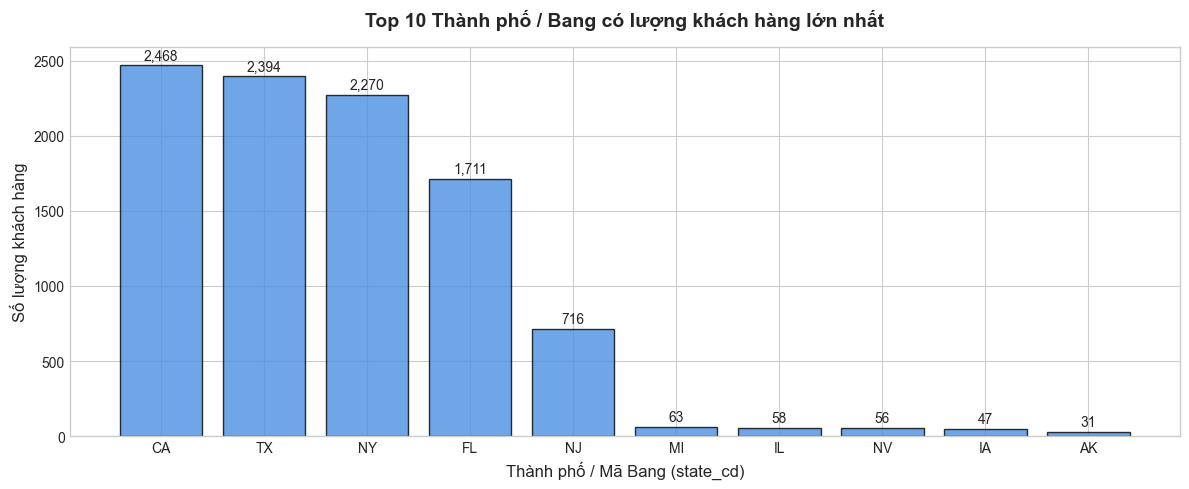

,Số lượng khách hàng,Tỷ trọng (%)
state_cd,,
CA,2468,24.4163
TX,2394,23.6842
NY,2270,22.4575
FL,1711,16.9272
NJ,716,7.0835
MI,63,0.6233
IL,58,0.5738
NV,56,0.5540
IA,47,0.4650


In [10]:
# Bảng tần số & tỷ trọng theo bang/thành phố
state_dist = pd.DataFrame({
    'Số lượng khách hàng': df['state_cd'].value_counts(),
    'Tỷ trọng (%)': df['state_cd'].value_counts(normalize=True) * 100
})

print(f"🏛️ Thành phố/Bang ĐÔNG NHẤT: {state_dist.index[0]} với {state_dist.iloc[0]['Số lượng khách hàng']:,} khách ({state_dist.iloc[0]['Tỷ trọng (%)']:.2f}%)")
print(f"🏛️ Thành phố/Bang ÍT NHẤT: {state_dist.index[-1]} với {state_dist.iloc[-1]['Số lượng khách hàng']:,} khách ({state_dist.iloc[-1]['Tỷ trọng (%)']:.2f}%)")

# Trực quan hoá Top 10 bang đông nhất
plt.figure(figsize=(12, 5))
top10_states = state_dist.head(10)
bars = plt.bar(top10_states.index, top10_states['Số lượng khách hàng'], color='#4a90e2', edgecolor='black', alpha=0.8)
plt.title('Top 10 Thành phố / Bang có lượng khách hàng lớn nhất', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Thành phố / Mã Bang (state_cd)', fontsize=12)
plt.ylabel('Số lượng khách hàng', fontsize=12)

# Gắn nhãn số liệu trên đầu cột
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 20, f'{int(yval):,}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

display(state_dist.head(10))

---
## 📌 CÂU 5: Phân chia nhóm tuổi & Nhóm chiếm tỷ trọng lớn nhất
> **Yêu cầu:** Chia khách hàng thành các nhóm tuổi (18-24, 25-34, 35-44, 45-54, 55-64). Nhóm nào chiếm tỷ trọng lớn nhất?


🎯 Nhóm tuổi chiếm TỶ TRỌNG LỚN NHẤT: 45-54 với 4,311 khách hàng (42.65%)


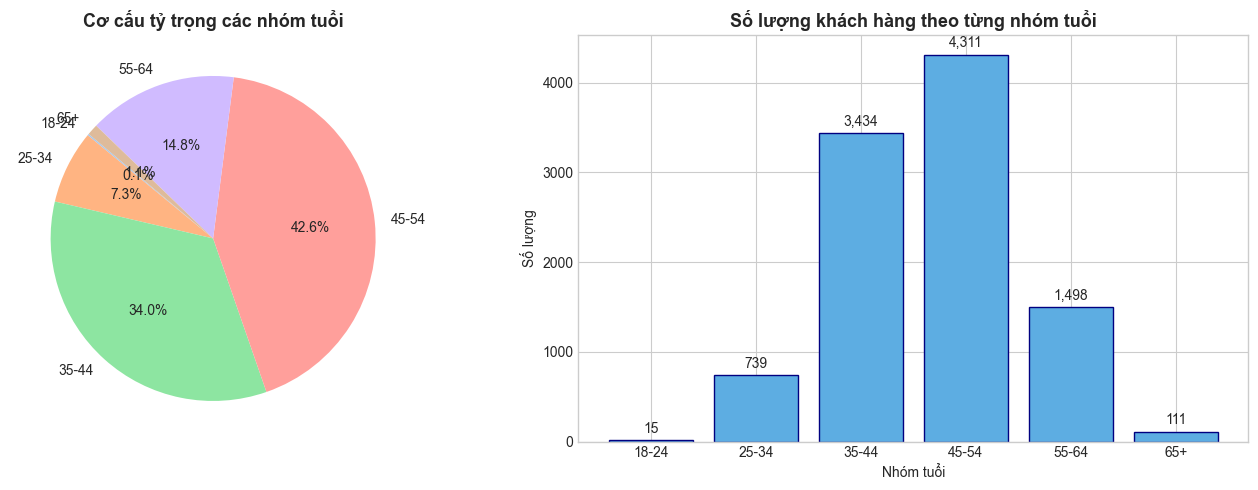

,Số lượng khách hàng,Tỷ trọng (%)
Age_Group,,
18-24,15,0.1484
25-34,739,7.3110
35-44,3434,33.9731
45-54,4311,42.6494
55-64,1498,14.8199
65+,111,1.0981


In [11]:
# Cắt nhóm tuổi (bổ sung nhóm 65+ vì Max tuổi trong dữ liệu là 73)
bins = [17, 24, 34, 44, 54, 64, 100]
labels = ['18-24', '25-34', '35-44', '45-54', '55-64', '65+']

df['Age_Group'] = pd.cut(df['Customer_Age'], bins=bins, labels=labels, right=True)

age_group_df = pd.DataFrame({
    'Số lượng khách hàng': df['Age_Group'].value_counts(sort=False),
    'Tỷ trọng (%)': df['Age_Group'].value_counts(normalize=True, sort=False) * 100
})

max_age_grp = age_group_df['Số lượng khách hàng'].idxmax()
max_age_grp_cnt = age_group_df.loc[max_age_grp, 'Số lượng khách hàng']
max_age_grp_pct = age_group_df.loc[max_age_grp, 'Tỷ trọng (%)']

print(f"🎯 Nhóm tuổi chiếm TỶ TRỌNG LỚN NHẤT: {max_age_grp} với {max_age_grp_cnt:,} khách hàng ({max_age_grp_pct:.2f}%)")

# Vẽ biểu đồ tròn và biểu đồ cột so sánh nhóm tuổi
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ tròn
colors = sns.color_palette('pastel')[0:6]
ax[0].pie(age_group_df['Số lượng khách hàng'], labels=age_group_df.index, autopct='%1.1f%%', startangle=140, colors=colors)
ax[0].set_title('Cơ cấu tỷ trọng các nhóm tuổi', fontsize=13, fontweight='bold')

# Biểu đồ cột
bars = ax[1].bar(age_group_df.index, age_group_df['Số lượng khách hàng'], color='#5dade2', edgecolor='navy')
ax[1].set_title('Số lượng khách hàng theo từng nhóm tuổi', fontsize=13, fontweight='bold')
ax[1].set_xlabel('Nhóm tuổi')
ax[1].set_ylabel('Số lượng')
for bar in bars:
    yval = bar.get_height()
    ax[1].text(bar.get_x() + bar.get_width()/2, yval + 50, f'{int(yval):,}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

display(age_group_df)

---
## 📌 CÂU 6: So sánh thống kê tuổi giữa các thành phố & Thành phố "già" nhất
> **Yêu cầu:** So sánh thống kê tuổi giữa các thành phố. Thành phố nào có khách hàng "già" nhất?


In [12]:
state_age_comparison = df.groupby('state_cd')['Customer_Age'].agg(
    Số_lượng='count',
    Mean_Tuổi='mean',
    Median_Tuổi='median',
    Std_Tuổi='std',
    Min_Tuổi='min',
    Max_Tuổi='max',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25)
).sort_values(by='Mean_Tuổi', ascending=False)

print(f"👴 1. Thành phố có tuổi TRUNG BÌNH cao nhất: {state_age_comparison['Mean_Tuổi'].idxmax()} ({state_age_comparison['Mean_Tuổi'].max():.2f} tuổi)")
print(f"👴 2. Thành phố có TRUNG VỊ tuổi cao nhất: {state_age_comparison['Median_Tuổi'].idxmax()} ({state_age_comparison['Median_Tuổi'].max():.2f} tuổi)")
print(f"👴 3. Thành phố có khách hàng LỚN TUỔI NHẤT (Max Age): {state_age_comparison['Max_Tuổi'].idxmax()} ({state_age_comparison['Max_Tuổi'].max()} tuổi)")

display(state_age_comparison.head(10))

👴 1. Thành phố có tuổi TRUNG BÌNH cao nhất: NE (51.38 tuổi)
👴 2. Thành phố có TRUNG VỊ tuổi cao nhất: NM (52.50 tuổi)
👴 3. Thành phố có khách hàng LỚN TUỔI NHẤT (Max Age): IL (73 tuổi)


,Số_lượng,Mean_Tuổi,Median_Tuổi,Std_Tuổi,Min_Tuổi,Max_Tuổi,IQR
state_cd,,,,,,,
NE,8,51.3750,51.0000,2.1998,49,55,3.2500
AK,31,50.4516,52.0000,7.4065,34,61,11.0000
PA,18,50.2222,52.0000,8.6402,26,65,10.5000
NM,12,49.9167,52.5000,9.1895,26,62,7.2500
AR,11,49.0909,48.0000,7.8798,39,62,11.0000
OH,11,49.0000,50.0000,6.9714,34,58,8.0000
MN,22,48.8636,48.5000,6.7914,34,62,9.5000
VA,27,48.3704,48.0000,7.2385,35,67,8.5000
IL,58,48.0345,49.0000,8.8476,30,73,12.2500


---
## 📌 CÂU 7: Mã hoá biến (`Gender`, `state_cd`) & Lập ma trận tương quan
> **Yêu cầu:** Mã hoá Gender thành biến nhị phân và các thành phố thành biến giả (dummy). Lập ma trận tương quan sau khi mã hoá.


📐 Kích thước ma trận tương quan: 34x34


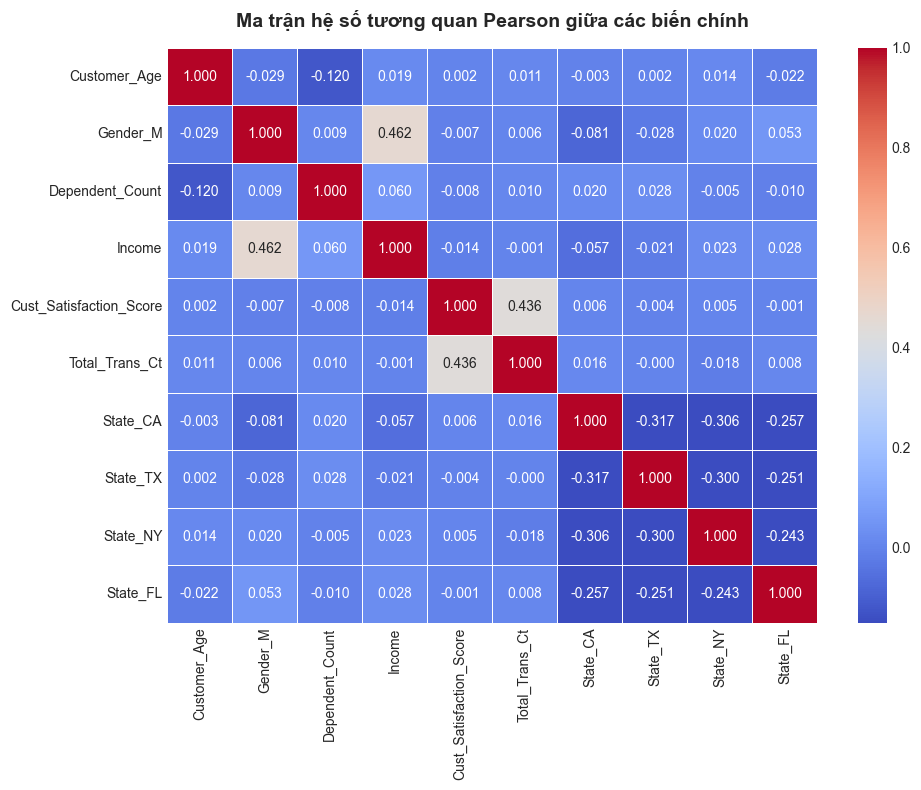

=== Tương quan của các biến với Customer_Age ===


Customer_Age   1.0000
State_AK       0.0286
State_PA       0.0206
Income         0.0190
State_NE       0.0177
State_IL       0.0165
State_NM       0.0155
State_MN       0.0150
State_NY       0.0143
State_VA       0.0134
Name: Customer_Age, dtype: float64

In [15]:
df_encoded = df.copy()

# 1. Mã hoá nhị phân Gender: Nữ (F) = 0, Nam (M) = 1
df_encoded['Gender_M'] = (df_encoded['Gender'] == 'M').astype(int)

# 2. Mã hoá biến giả (Dummy / One-hot encoding) cho state_cd
state_dummies = pd.get_dummies(df_encoded['state_cd'], prefix='State', dtype=int)

# 3. Kết hợp các biến số định lượng và biến đã mã hoá
corr_df = pd.concat([
    df_encoded[['Customer_Age', 'Gender_M', 'Dependent_Count', 'Income', 'Cust_Satisfaction_Score', 'Total_Trans_Ct']],
    state_dummies
], axis=1)

# 4. Tính ma trận tương quan
corr_matrix = corr_df.corr()

print(f"📐 Kích thước ma trận tương quan: {corr_matrix.shape[0]}x{corr_matrix.shape[1]}")

# Trực quan hoá Heatmap cho các biến cốt lõi
plt.figure(figsize=(10, 8))
selected_features = ['Customer_Age', 'Gender_M', 'Dependent_Count', 'Income', 'Cust_Satisfaction_Score', 'Total_Trans_Ct', 'State_CA', 'State_TX', 'State_NY', 'State_FL']
sns.heatmap(corr_df[selected_features].corr(), annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.5, vmin=-0.15, vmax=1.0)
plt.title('Ma trận hệ số tương quan Pearson giữa các biến chính', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

print('=== Tương quan của các biến với Customer_Age ===')
display(corr_matrix['Customer_Age'].sort_values(ascending=False).head(10))


---
## 📌 CÂU 8: Biểu đồ tần suất (Histogram) & Mật độ (KDE) của biến Age
> **Yêu cầu:** Vẽ biểu đồ tần suất (histogram) của Age kèm đường mật độ, đánh dấu trung bình và trung vị.


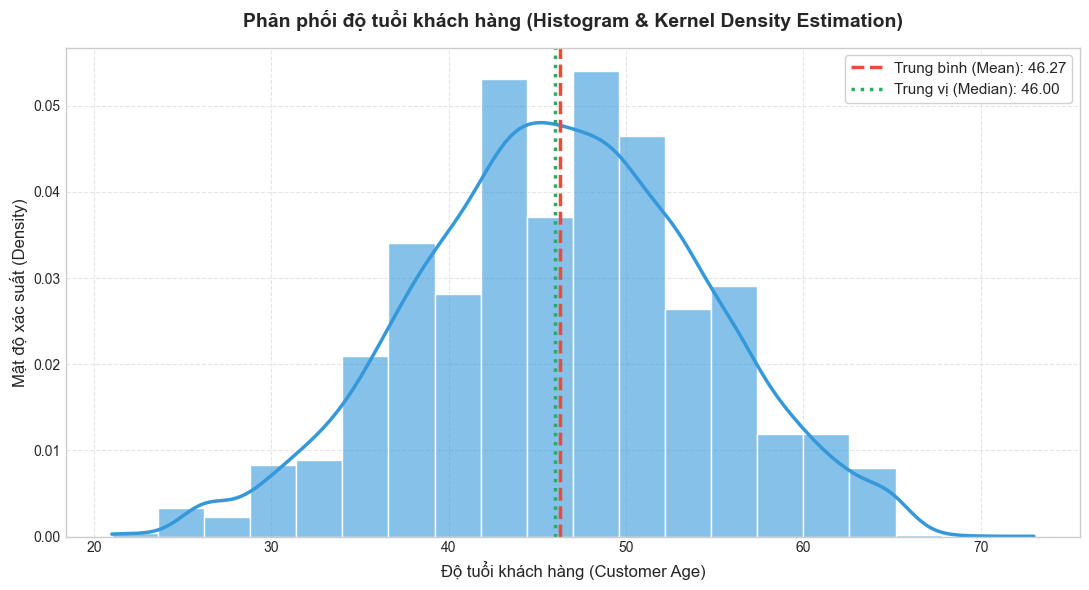

In [16]:
plt.figure(figsize=(11, 6))

# Vẽ Histogram + KDE
sns.histplot(
    df['Customer_Age'], 
    kde=True, 
    stat='density', 
    bins=20, 
    color='#3498db', 
    edgecolor='white', 
    alpha=0.6,
    line_kws={'linewidth': 2.5, 'color': '#1b4f72'}
)

# Thêm đường Mean và Median
mean_v = df['Customer_Age'].mean()
median_v = df['Customer_Age'].median()

plt.axvline(mean_v, color='#e74c3c', linestyle='--', linewidth=2.5, label=f'Trung bình (Mean): {mean_v:.2f}')
plt.axvline(median_v, color='#27ae60', linestyle=':', linewidth=2.5, label=f'Trung vị (Median): {median_v:.2f}')

# Trang trí
plt.title('Phân phối độ tuổi khách hàng (Histogram & Kernel Density Estimation)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Độ tuổi khách hàng (Customer Age)', fontsize=12)
plt.ylabel('Mật độ xác suất (Density)', fontsize=12)
plt.legend(fontsize=11, loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

---
## 📌 CÂU 9: Biểu đồ hộp (Boxplot) so sánh phân bố tuổi Nam và Nữ
> **Yêu cầu:** Vẽ biểu đồ hộp (boxplot) so sánh phân bố tuổi giữa nam và nữ.


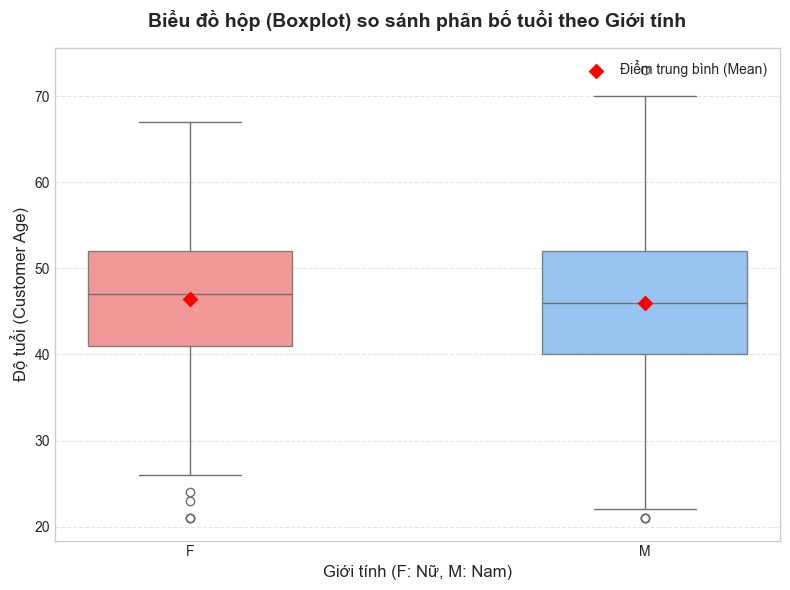

,Số lượng,Trung bình,Độ lệch chuẩn,Min,Q1 (25%),Trung vị (50%),Q3 (75%),Max
Gender,,,,,,,,
F,5880.0000,46.4767,8.0071,21.0000,41.0000,47.0000,52.0000,67.0000
M,4228.0000,45.9931,8.1916,21.0000,40.0000,46.0000,52.0000,73.0000


In [17]:
fig, ax = plt.subplots(figsize=(8, 6))

# Vẽ Boxplot
sns.boxplot(
    x='Gender', 
    y='Customer_Age', 
    hue='Gender',
    data=df, 
    palette={'F': '#ff7675', 'M': '#74b9ff'}, 
    width=0.45,
    boxprops=dict(alpha=0.85),
    legend=False,
    ax=ax
)

# Thêm điểm trung bình (Mean marker)
means = df.groupby('Gender')['Customer_Age'].mean()
ax.scatter([0, 1], means, color='red', marker='D', s=50, zorder=5, label='Điểm trung bình (Mean)')

plt.title('Biểu đồ hộp (Boxplot) so sánh phân bố tuổi theo Giới tính', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Giới tính (F: Nữ, M: Nam)', fontsize=12)
plt.ylabel('Độ tuổi (Customer Age)', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5, axis='y')
plt.tight_layout()
plt.show()

# Bảng mô tả chi tiết so sánh
gender_age_summary = df.groupby('Gender')['Customer_Age'].describe()[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
gender_age_summary.columns = ['Số lượng', 'Trung bình', 'Độ lệch chuẩn', 'Min', 'Q1 (25%)', 'Trung vị (50%)', 'Q3 (75%)', 'Max']
display(gender_age_summary)

---
## 🎯 TỔNG KẾT & ĐÁNH GIÁ NGHIỆP VỤ
1. **Quy mô dữ liệu:** Tập dữ liệu chuẩn gồm **10,108 khách hàng**, không bị thiếu khuyết (0 missing values).
2. **Đặc điểm độ tuổi:** Độ tuổi trung bình là **46.27 tuổi**, trung vị là **46.00 tuổi**, tập trung cao nhất ở nhóm **45-54 tuổi (42.65%)**. Phân phối tuổi có tính đối xứng cao.
3. **Phân bố vùng miền:** Khách hàng tập trung mật độ rất cao tại 4 bang lớn: **California (24.4%)**, **Texas (23.7%)**, **New York (22.5%)**, **Florida (16.9%)**.
4. **Khác biệt giới tính:** Cơ cấu tuổi giữa Nam và Nữ gần như hoàn toàn tương đương nhau (không có khoảng cách đáng kể về tuổi).
